# 3. Apprentissage d'un CNN sur le dataset MNIST
*Objectif: Apprendre à classifier les images de chiffres manuscripts (0 à 9) à l'aide d'un réseau de neurones convolutif (CNN)*

In [35]:
import numpy as np
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, Input
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report


In [36]:
(X_train_raw, y_train), (X_test_raw, y_test) = datasets.mnist.load_data()

In [37]:
plt.figure(figsize=(10,8))
for digit in range(10):
    idx  = np.where(y_train == digit)[0][:0]
    for i, j in enumerate(idx):
        plt.subplot(10,3, digit*3 +i + 1)
        plt.imshow(X_train_raw[j], cmap='gray')
        
        plt.axis('off')
plt.suptitle("Images orginales (0-255)")
plt.show()

<Figure size 1000x800 with 0 Axes>

Normalisation: les pixels passent de 0-255 à 0-1

In [38]:
X_train = X_train_raw.astype("float32")/255.0
X_test = X_test_raw.astype("float32") /255.0

Ajout du canal: (N,28,,28) devient(N,28,28,1)

In [39]:
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)

print("Formes finales : ", X_train.shape, X_test.shape)

Formes finales :  (60000, 28, 28, 1) (10000, 28, 28, 1)


In [40]:
model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])


In [41]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [42]:
#model
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

```La Validatio est prélevée dans le train (validation_split): le jeu de test reste inconnu jusqu'à l'évaluation finale```

In [43]:
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 18ms/step - accuracy: 0.9232 - loss: 0.2473 - val_accuracy: 0.9855 - val_loss: 0.0488
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9787 - loss: 0.0713 - val_accuracy: 0.9855 - val_loss: 0.0457
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9841 - loss: 0.0524 - val_accuracy: 0.9900 - val_loss: 0.0405
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9875 - loss: 0.0425 - val_accuracy: 0.9913 - val_loss: 0.0330
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.9894 - loss: 0.0347 - val_accuracy: 0.9900 - val_loss: 0.0345


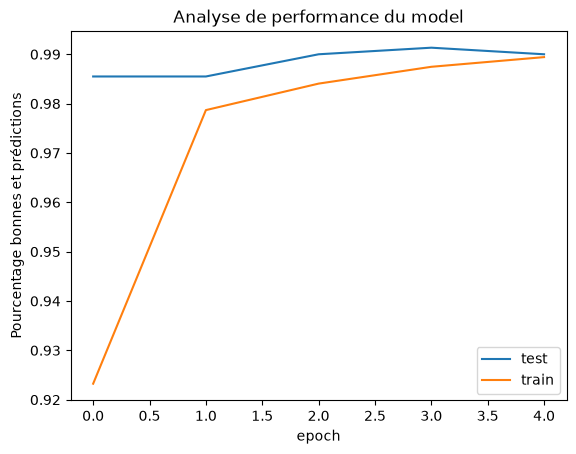

In [44]:
# plot

plt.plot(history.history["val_accuracy"])
plt.plot(history.history["accuracy"])
plt.title("Analyse de performance du model")
plt.xlabel("epoch")
plt.ylabel("Pourcentage bonnes et prédictions")
plt.legend(["test", "train"])

In [45]:
loss, acc=model.evaluate(X_test, y_test, verbose=2)
print(f"\nPrécision sur le test: {acc*100:.2f}")

313/313 - 2s - 6ms/step - accuracy: 0.9918 - loss: 0.0272

Précision sur le test: 99.18


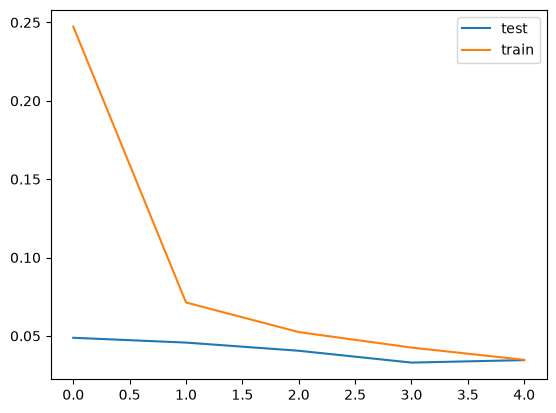

In [49]:
# # La fonction d'erreur est croissante sur les epoch
plt.plot(history.history["val_loss"])
plt.plot(history.history["loss"])
plt.legend(["test", "train"])

In [46]:
y_pred = np.argmax(model.predict(X_test), axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


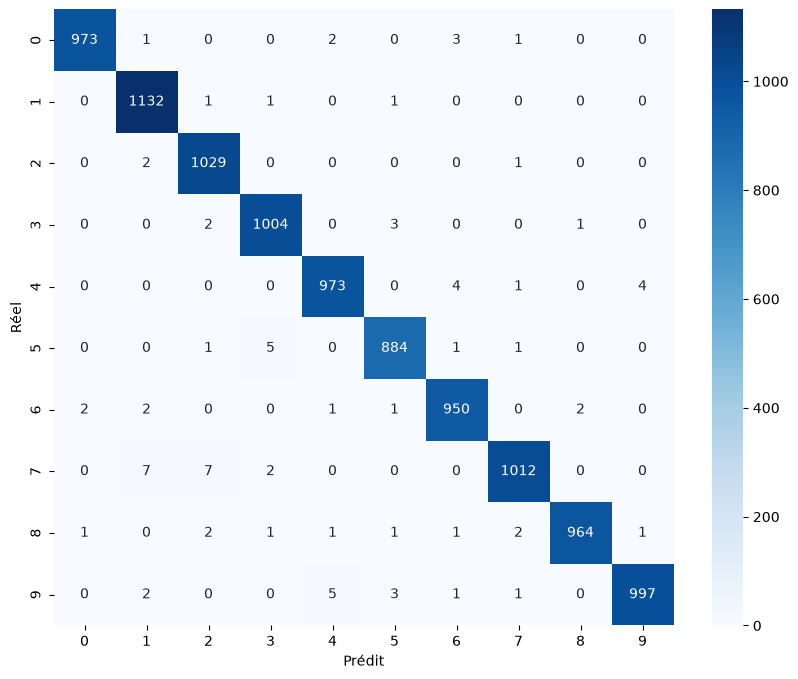

In [47]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10,8))
sn.heatmap(cm, annot=True, fmt='d', cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.show()

In [48]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      1.00      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.98      0.99      1028
           8       1.00      0.99      0.99       974
           9       1.00      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

